# AI101 Mini-Project Group-26
### Chronic Kidney Disease Prediction Using Logistic Regression

## Section 1 – Dataset Understanding

## 1. Import Required Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load the Dataset

In [ ]:
df = pd.read_csv("Chronic_Kidney_Disease_data.csv")

## 3. Understand the Dataset

### 3.1 Display First Five Rows

In [ ]:
df.head()

,PatientID,Age,Gender,Ethnicity,SocioeconomicStatus,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,...,Itching,QualityOfLifeScore,HeavyMetalsExposure,OccupationalExposureChemicals,WaterQuality,MedicalCheckupsFrequency,MedicationAdherence,HealthLiteracy,Diagnosis,DoctorInCharge
0,1,71,0,0,0,2,31.069414,1,5.128112,1.676220,...,7.556302,76.076800,0,0,1,1.018824,4.966808,9.871449,1,Confidential
1,2,34,0,0,1,3,29.692119,1,18.609552,8.377574,...,6.836766,40.128498,0,0,0,3.923538,8.189275,7.161765,1,Confidential
2,3,80,1,1,0,1,37.394822,1,11.882429,9.607401,...,2.144722,92.872842,0,1,1,1.429906,7.624028,7.354632,1,Confidential
3,4,40,0,2,0,1,31.329680,0,16.020165,0.408871,...,7.077188,90.080321,0,0,0,3.226416,3.282688,6.629587,1,Confidential
4,5,43,0,1,1,2,23.726311,0,7.944146,0.780319,...,3.553118,5.258372,0,0,1,0.285466,3.849498,1.437385,1,Confidential


### 3.2 Dataset Shape

In [ ]:
print("Dataset Shape:", df.shape)

Dataset Shape: (1659, 54)


### 3.3 Dataset Information

In [ ]:
print("Column Names :",df.columns.tolist())

Column Names : ['PatientID', 'Age', 'Gender', 'Ethnicity', 'SocioeconomicStatus', 'EducationLevel', 'BMI', 'Smoking', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality', 'SleepQuality', 'FamilyHistoryKidneyDisease', 'FamilyHistoryHypertension', 'FamilyHistoryDiabetes', 'PreviousAcuteKidneyInjury', 'UrinaryTractInfections', 'SystolicBP', 'DiastolicBP', 'FastingBloodSugar', 'HbA1c', 'SerumCreatinine', 'BUNLevels', 'GFR', 'ProteinInUrine', 'ACR', 'SerumElectrolytesSodium', 'SerumElectrolytesPotassium', 'SerumElectrolytesCalcium', 'SerumElectrolytesPhosphorus', 'HemoglobinLevels', 'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL', 'CholesterolTriglycerides', 'ACEInhibitors', 'Diuretics', 'NSAIDsUse', 'Statins', 'AntidiabeticMedications', 'Edema', 'FatigueLevels', 'NauseaVomiting', 'MuscleCramps', 'Itching', 'QualityOfLifeScore', 'HeavyMetalsExposure', 'OccupationalExposureChemicals', 'WaterQuality', 'MedicalCheckupsFrequency', 'MedicationAdherence', 'HealthLiteracy', 'Diagnosis',

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1659 entries, 0 to 1658
Data columns (total 54 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   PatientID                      1659 non-null   int64  
 1   Age                            1659 non-null   int64  
 2   Gender                         1659 non-null   int64  
 3   Ethnicity                      1659 non-null   int64  
 4   SocioeconomicStatus            1659 non-null   int64  
 5   EducationLevel                 1659 non-null   int64  
 6   BMI                            1659 non-null   float64
 7   Smoking                        1659 non-null   int64  
 8   AlcoholConsumption             1659 non-null   float64
 9   PhysicalActivity               1659 non-null   float64
 10  DietQuality                    1659 non-null   float64
 11  SleepQuality                   1659 non-null   float64
 12  FamilyHistoryKidneyDisease     1659 non-null   int64  
 13 

### 3.4 Statistical Summary

In [ ]:
df.describe(include="all")

,PatientID,Age,Gender,Ethnicity,SocioeconomicStatus,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,...,Itching,QualityOfLifeScore,HeavyMetalsExposure,OccupationalExposureChemicals,WaterQuality,MedicalCheckupsFrequency,MedicationAdherence,HealthLiteracy,Diagnosis,DoctorInCharge
count,1659.000000,1659.000000,1659.000000,1659.00000,1659.000000,1659.000000,1659.000000,1659.000000,1659.000000,1659.000000,...,1659.000000,1659.000000,1659.000000,1659.000000,1659.000000,1659.000000,1659.000000,1659.000000,1659.000000,1659
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Confidential
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1659
mean,830.000000,54.441230,0.515371,0.71308,0.977697,1.693189,27.620049,0.292948,9.969831,5.024247,...,5.054869,49.730659,0.044002,0.103074,0.197107,2.000336,4.947788,5.144973,0.918626,NaN
std,479.056364,20.549757,0.499914,1.00043,0.776686,0.910611,7.288670,0.455252,5.798787,2.866274,...,2.880460,27.827593,0.205162,0.304147,0.397934,1.141635,2.869959,2.901138,0.273492,NaN
min,1.000000,20.000000,0.000000,0.00000,0.000000,0.000000,15.033888,0.000000,0.021740,0.001186,...,0.013697,0.087256,0.000000,0.000000,0.000000,0.001082,0.005392,0.004436,0.000000,NaN
25%,415.500000,36.000000,0.000000,0.00000,0.000000,1.000000,21.471449,0.000000,5.051156,2.555038,...,2.532867,26.991708,0.000000,0.000000,0.000000,1.005802,2.498119,2.569561,1.000000,NaN
50%,830.000000,54.000000,1.000000,0.00000,1.000000,2.000000,27.652077,0.000000,9.951503,5.072395,...,5.087086,48.970075,0.000000,0.000000,0.000000,2.040635,4.974069,5.182949,1.000000,NaN
75%,1244.500000,72.000000,1.000000,1.00000,2.000000,2.000000,34.015849,1.000000,14.967100,7.460563,...,7.552093,73.913997,0.000000,0.000000,0.000000,2.947213,7.499783,7.733253,1.000000,NaN


#### checking missing values


In [ ]:
df.isnull().sum()

PatientID                        0
Age                              0
Gender                           0
Ethnicity                        0
SocioeconomicStatus              0
EducationLevel                   0
BMI                              0
Smoking                          0
AlcoholConsumption               0
PhysicalActivity                 0
DietQuality                      0
SleepQuality                     0
FamilyHistoryKidneyDisease       0
FamilyHistoryHypertension        0
FamilyHistoryDiabetes            0
PreviousAcuteKidneyInjury        0
UrinaryTractInfections           0
SystolicBP                       0
DiastolicBP                      0
FastingBloodSugar                0
HbA1c                            0
SerumCreatinine                  0
BUNLevels                        0
GFR                              0
ProteinInUrine                   0
ACR                              0
SerumElectrolytesSodium          0
SerumElectrolytesPotassium       0
SerumElectrolytesCal

In [ ]:
print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 0


#### checking duplicate rows

In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


### 3.5 Target Variable Distribution

In [ ]:
print(df["Diagnosis"].value_counts(dropna=False))

Diagnosis
1    1524
0     135
Name: count, dtype: int64


#### In Percentage

In [ ]:
print(
    df["Diagnosis"]
    .value_counts(normalize=True, dropna=False) * 100
)

Diagnosis
1    91.862568
0     8.137432
Name: proportion, dtype: float64


#### Visualize Target Distribution

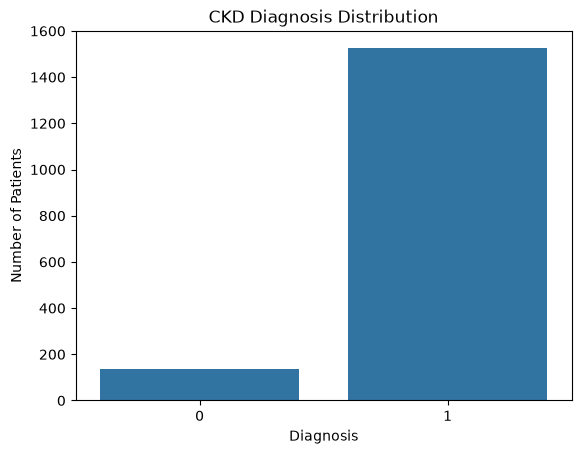

In [ ]:
sns.countplot(data=df, x="Diagnosis")
plt.title("CKD Diagnosis Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Patients")
plt.show()

#### Number of Unique Values in each Column

In [ ]:
for column in df.columns:
    print(column, ":", df[column].nunique())

PatientID : 1659
Age : 71
Gender : 2
Ethnicity : 4
SocioeconomicStatus : 3
EducationLevel : 4
BMI : 1659
Smoking : 2
AlcoholConsumption : 1659
PhysicalActivity : 1659
DietQuality : 1659
SleepQuality : 1659
FamilyHistoryKidneyDisease : 2
FamilyHistoryHypertension : 2
FamilyHistoryDiabetes : 2
PreviousAcuteKidneyInjury : 2
UrinaryTractInfections : 2
SystolicBP : 90
DiastolicBP : 60
FastingBloodSugar : 1659
HbA1c : 1659
SerumCreatinine : 1659
BUNLevels : 1659
GFR : 1659
ProteinInUrine : 1659
ACR : 1659
SerumElectrolytesSodium : 1659
SerumElectrolytesPotassium : 1659
SerumElectrolytesCalcium : 1659
SerumElectrolytesPhosphorus : 1659
HemoglobinLevels : 1659
CholesterolTotal : 1659
CholesterolLDL : 1659
CholesterolHDL : 1659
CholesterolTriglycerides : 1659
ACEInhibitors : 2
Diuretics : 2
NSAIDsUse : 1659
Statins : 2
AntidiabeticMedications : 2
Edema : 2
FatigueLevels : 1659
NauseaVomiting : 1659
MuscleCramps : 1659
Itching : 1659
QualityOfLifeScore : 1659
HeavyMetalsExposure : 2
Occupational

### Identify Strongly Correlated Features

In [ ]:
# Select continuous numerical features
corr_features = [
    "Age", "BMI", "SystolicBP", "DiastolicBP",
    "FastingBloodSugar", "HbA1c", "SerumCreatinine",
    "BUNLevels", "GFR", "ProteinInUrine", "ACR",
    "SerumElectrolytesSodium", "SerumElectrolytesPotassium",
    "SerumElectrolytesCalcium", "SerumElectrolytesPhosphorus",
    "HemoglobinLevels", "CholesterolTotal",
    "CholesterolLDL", "CholesterolHDL",
    "CholesterolTriglycerides"
]

# Calculate correlation matrix
corr_matrix = df[corr_features].corr()

# Identify strongly correlated pairs
strong_corr = corr_matrix.where(
    corr_matrix.abs() > 0.7
).stack().reset_index()

strong_corr.columns = [
    "Feature 1", "Feature 2", "Correlation"
]

# Remove duplicate pairs and self-correlations
strong_corr = strong_corr[
    (strong_corr["Feature 1"] < strong_corr["Feature 2"])
]

print(strong_corr.to_string())

                       Feature 1                    Feature 2  Correlation
1                            Age                          BMI          NaN
2                            Age                   SystolicBP          NaN
3                            Age                  DiastolicBP          NaN
4                            Age            FastingBloodSugar          NaN
5                            Age                        HbA1c          NaN
6                            Age              SerumCreatinine          NaN
7                            Age                    BUNLevels          NaN
8                            Age                          GFR          NaN
9                            Age               ProteinInUrine          NaN
11                           Age      SerumElectrolytesSodium          NaN
12                           Age   SerumElectrolytesPotassium          NaN
13                           Age     SerumElectrolytesCalcium          NaN
14                       

## Dataset Exploration Summary

- **Total records**: 1659
- **Total columns**: 54
- **Target column**: Diagnosis
- **Missing values**: 0
- **Duplicate rows**: 0
- **Target distribution**: 1-1534 and 0-135
- **Class imbalance**: Yes
- **Columns requiring special attention**: DoctorInCharge(constant), PatientID, Diagnosis(imbalance), HeavyMetalsExposure(skewed), PreviousAcuteKidneyInjury(skewed), OccupationalExposureChemical(skewed).

### Correlation Analysis

The dataset contains 54 columns, including continuous numerical, categorical, and identifier features.

For correlation analysis, the 20 continuous numerical features were selected because Pearson correlation is appropriate for examining linear relationships between numerical variables.

A threshold of 0.7 (absolute value) was used to identify strong correlations.

The analysis did not identify any strongly correlated pairs among the selected features. Therefore, no columns were removed based on correlation analysis, and the features were retained for further model training.

## Section 2 – Data Preprocessing


## 1. Identify Target, Input Freatures

In [ ]:
target_column = "Diagnosis"

X = df.drop(columns=[target_column]) #Input Features
y = df[target_column] #Target Column

## 2. Identify Numerical and Categorical Features

In [ ]:
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool","string"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['PatientID', 'Age', 'Gender', 'Ethnicity', 'SocioeconomicStatus', 'EducationLevel', 'BMI', 'Smoking', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality', 'SleepQuality', 'FamilyHistoryKidneyDisease', 'FamilyHistoryHypertension', 'FamilyHistoryDiabetes', 'PreviousAcuteKidneyInjury', 'UrinaryTractInfections', 'SystolicBP', 'DiastolicBP', 'FastingBloodSugar', 'HbA1c', 'SerumCreatinine', 'BUNLevels', 'GFR', 'ProteinInUrine', 'ACR', 'SerumElectrolytesSodium', 'SerumElectrolytesPotassium', 'SerumElectrolytesCalcium', 'SerumElectrolytesPhosphorus', 'HemoglobinLevels', 'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL', 'CholesterolTriglycerides', 'ACEInhibitors', 'Diuretics', 'NSAIDsUse', 'Statins', 'AntidiabeticMedications', 'Edema', 'FatigueLevels', 'NauseaVomiting', 'MuscleCramps', 'Itching', 'QualityOfLifeScore', 'HeavyMetalsExposure', 'OccupationalExposureChemicals', 'WaterQuality', 'MedicalCheckupsFrequency', 'MedicationAdherence', 'HealthLiteracy']

Catego

## 3. Handle Missing Values

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler 

# Missing Numeric Values Replaced by Median
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Missing Categorical Values Replaced By Most-Frequent Value
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

from sklearn.compose import ColumnTransformer

# Combining Numeric and Categorical Transformers through ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

## 4. Perform Train-Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


In [ ]:
#Verify train test splits

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1327, 53)
X_test shape: (332, 53)
y_train shape: (1327,)
y_test shape: (332,)


## Section 3 – Model Development

Algorithm: Logistic Regression

Type: Supervised Machine Learning

Task: Binary Classification

## 1. Importing Required Libraries



In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

## 2. Creating the Logistic Regression model

In [ ]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=12828,
        solver="liblinear",
        random_state=42
    ))
])

## 3. Training the model

In [ ]:
model.fit(X_train, y_train)
print("Model Trained Successfully")

Model Trained Successfully


### 3.1 Learning Curve

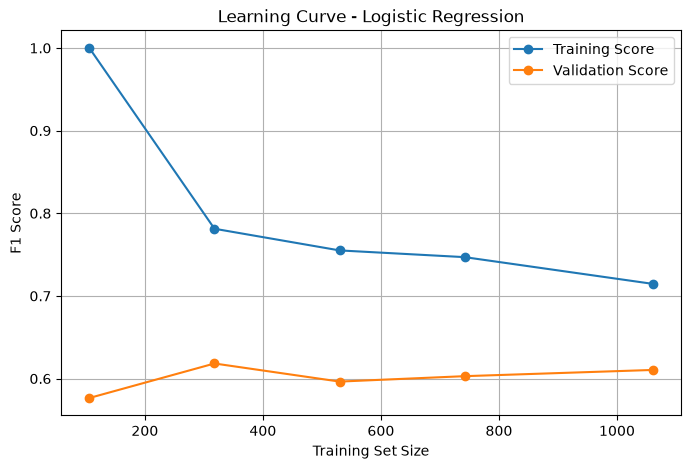

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

train_sizes, train_scores, validation_scores = learning_curve(
    model,
    X_train,
    y_train,
    cv=5,
    scoring="f1_macro",
    train_sizes=[0.1, 0.3, 0.5, 0.7, 1.0],
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, marker='o', label="Training Score")
plt.plot(train_sizes, validation_mean, marker='o', label="Validation Score")

plt.xlabel("Training Set Size")
plt.ylabel("F1 Score")
plt.title("Learning Curve - Logistic Regression")
plt.legend()
plt.grid()
plt.savefig("training_plots/learning_curve.png", dpi=300, bbox_inches="tight")
plt.show()

### **Understanding the Logistic Regression Learning Curve**

* **Overfitting with Small Data:** At the start (around 200 data points), the model shows a massive gap between the **Training Score (Blue)** and the **Validation Score (Orange)**. It performs nearly perfectly on the data it knows but poorly on new data, meaning it overfits when data is scarce.
* **Improvement with More Data:** As the training set size increases toward 1,000 samples, the orange validation line steadily climbs. This proves that feeding more patient records into the model directly improves its ability to make accurate real-world predictions.
* **The Complexity Plateau:** Even at its maximum size of 1,000 samples, the validation score flattens out at around a **0.64 F1-Score**, and the training score continues to drop. This tells us the model has reached its limit; a simple straight decision boundary (Logistic Regression) is hitting a structural ceiling and cannot fully capture the complex, hidden relationships inside this kidney disease dataset.


### 3.2 Loss Curve

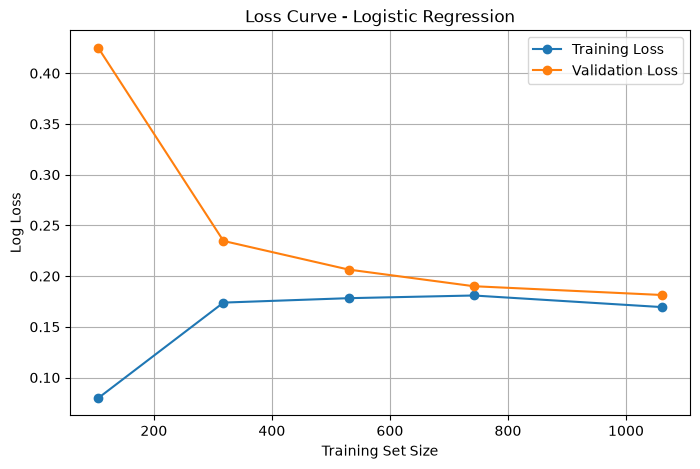

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import log_loss

train_losses = []
validation_losses = []

for size in train_sizes:
    temp_model = clone(model)
    temp_model.fit(X_train.iloc[:size], y_train.iloc[:size])

    train_prob = temp_model.predict_proba(X_train.iloc[:size])
    val_prob = temp_model.predict_proba(X_train)

    train_losses.append(log_loss(y_train.iloc[:size], train_prob))
    validation_losses.append(log_loss(y_train, val_prob))

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_losses, marker='o', label="Training Loss")
plt.plot(train_sizes, validation_losses, marker='o', label="Validation Loss")

plt.xlabel("Training Set Size")
plt.ylabel("Log Loss")
plt.title("Loss Curve - Logistic Regression")
plt.legend()
plt.grid()
plt.savefig("training_plots/loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()

### **Key Takeaways from the Loss Curve**

* **Initial Optimization Challenge:** At the smallest training size, the **Validation Loss (Orange)** is exceptionally high (~0.42), while the **Training Loss (Blue)** is unusually low (~0.12). This massive gap indicates the model heavily overfits the training subset and generalizes very poorly to unseen patient records early on.
* **Convergence with Scaled Data:** As more patient data is introduced (moving past 400 training samples), the curves dramatically converge. The training loss rises and the validation loss falls steadily, showing that the model becomes more stable and realistic as the sample volume grows.
* **High Final Bias / Error Floor:** Even at the maximum training size of 1,000 samples, both losses plateau and flatten out at a relatively high value (~0.23). The lines running flat and parallel without dropping further indicates high bias; the linear model cannot minimize the loss any further because it lacks the mathematical complexity to map the full spectrum of risk factors in the dataset.


## 4. Making predicitons

In [ ]:
y_pred = model.predict(X_test)

## 5. Comparing Actual and Predicted Diagnoses

In [ ]:
comparison = pd.DataFrame({
    "Actual Diagnosis": y_test.to_numpy(),
    "Predicted Diagnosis": y_pred
})

display(comparison.head(10))

,Actual Diagnosis,Predicted Diagnosis
0,1,1
1,0,1
2,1,1
3,1,1
4,1,1
5,1,1
6,1,1
7,1,1
8,1,1
9,1,1


#### Section 4 – Model Evaluation

## 1. Import evaluation tools

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

## 2. Calculate accuracy

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", np.round(accuracy,3))

Accuracy: 0.919


## 3. Calculate precision

In [ ]:
precision = precision_score(
    y_test,
    y_pred,
    average="binary",
    zero_division=0
)

print("Precision:", np.round(precision,3))

Precision: 0.937


## 4. Calculate recall

In [ ]:
recall = recall_score(
    y_test,
    y_pred,
    average="binary",
    zero_division=0
)

print("Recall:", np.round(recall,3))

Recall: 0.977


## 5. Calculate F1-score

In [ ]:
f1 = f1_score(
    y_test,
    y_pred,
    average="binary",
    zero_division=0
)

print("F1 Score:", np.round(f1,3))

F1 Score: 0.957


## 6. Create the confusion matrix

In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[  7  20]
 [  7 298]]


### Visualise it

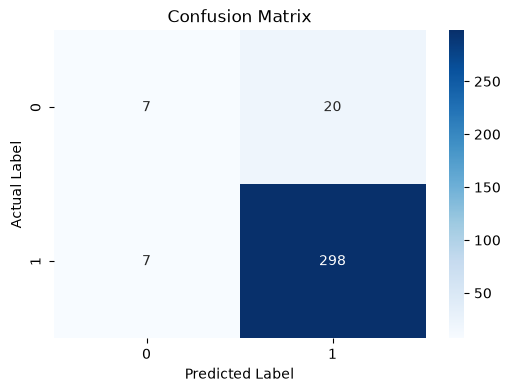

In [ ]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.savefig("results/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

 #### Model Evaluation: Confusion Matrix Insights

The confusion matrix visually demonstrates how well our machine learning model distinguishes between patients with Chronic Kidney Disease (**CKD**) and healthy individuals (**No CKD**). 

##### 📊 Matrix Breakdown
* **True Positives (TP) = 298:** The model correctly identified 298 individuals who actually have Chronic Kidney Disease.
* **True Negatives (TN) = 7:** The model correctly identified 7 individuals who do not have Chronic Kidney Disease.
* **False Positives (FP) = 20:** The model incorrectly flagged 20 healthy individuals as having Chronic Kidney Disease.
* **False Negatives (FN) = 7:** The model missed 7 patients who actually have Chronic Kidney Disease, incorrectly predicting them as healthy.

##### 📈 Key Performance Indicators
* **Overall Accuracy (~91.87%):** Out of 332 total patients in the test set, the model made the correct prediction nearly 92% of the time.
* **High Sensitivity / Recall (~97.70%):** The model successfully captured the vast majority of positive CKD cases. In medical diagnostics, a high recall rate is critical because it ensures that very few sick patients go unnoticed.
* **Balanced Precision (~93.71%):** When the model predicts a patient has CKD, it is highly reliable, with low rates of false alarms.

##### 🔍 Project Observation
While the overall accuracy and recall are highly promising for medical screening, the dataset appears to be heavily imbalanced toward positive CKD cases (305 CKD vs. 27 No CKD). Future work could explore balancing techniques like SMOTE or gathering more control samples to further enhance the model's ability to accurately predict healthy cases.

## 7. Generate the classification report

In [ ]:
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.50      0.26      0.34        27
           1       0.94      0.98      0.96       305

    accuracy                           0.92       332
   macro avg       0.72      0.62      0.65       332
weighted avg       0.90      0.92      0.91       332



## 8. Calculate prediction probabilities

In [ ]:
# Get predicted probabilities for the positive class (1)
y_prob = model.predict_proba(X_test)[:, 1]

print("Predicted Probabilities:")
print(np.round(y_prob[:10],3))

Predicted Probabilities:
[0.998 0.52  0.99  0.982 0.994 0.988 0.856 0.97  0.792 0.999]


## 9. ROC Curve and ROC-AUC Score

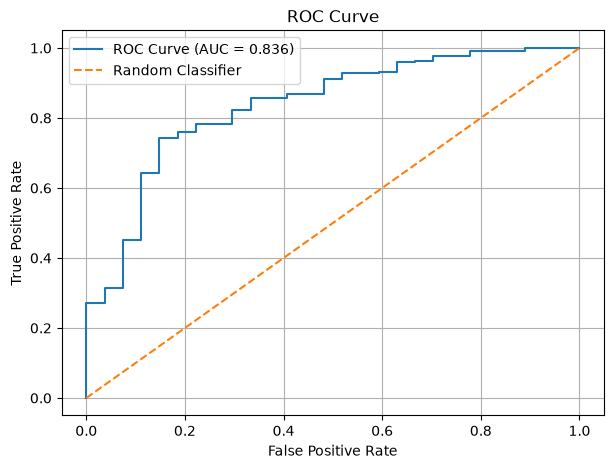

ROC-AUC Score: 0.836


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate False Positive Rate and True Positive Rate
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate ROC-AUC score
roc_auc = roc_auc_score(y_test, y_prob)

# Plot ROC Curve
plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.savefig("results/roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

print("ROC-AUC Score:", np.round(roc_auc,3))

#### Model Evaluation: ROC Curve Analysis

To assess the performance of our **Chronic Kidney Disease (CKD)** prediction model, we plotted the **Receiver Operating Characteristic (ROC)** curve and calculated the **Area Under the Curve (AUC)** shown above. 

##### Key Insights & Performance Interpretation:

* **Discriminative Power ($\text{AUC} = 0.836$):** The model achieves an AUC of **0.836**, indicating **good overall classification performance**. This means there is an **83.6% probability** that the model will correctly assign a higher disease risk score to a randomly selected CKD patient than to a healthy individual.
* **Comparison Against Baseline:** The blue step-curve sits substantially above the red dashed diagonal line ($\text{AUC} = 0.50$), confirming that the model performs significantly better than random guessing and has successfully captured relevant predictive patterns from the Kaggle dataset.
* **Step-Like Behavior:** The jagged, stair-step appearance of the curve is a characteristic visual artifact caused by a discrete, finite sample size in our test evaluation set as the classification threshold shifts.

##### Clinical Implementation & Threshold Tuning:
Depending on the clinical deployment goals, we can use this curve to fine-tune our classification threshold:
* **Screening Mode (High Sensitivity):** We can move along the curve to maximize the **True Positive Rate** to ensure early stages of CKD are rarely missed, minimizing dangerous False Negatives.
* **Diagnostic Mode (High Specificity):** Alternatively, we can adjust the threshold to minimize **False Positives**, protecting healthy patients from unnecessary anxiety and costly follow-up medical testing.


## 10. Precision-Recall Curve

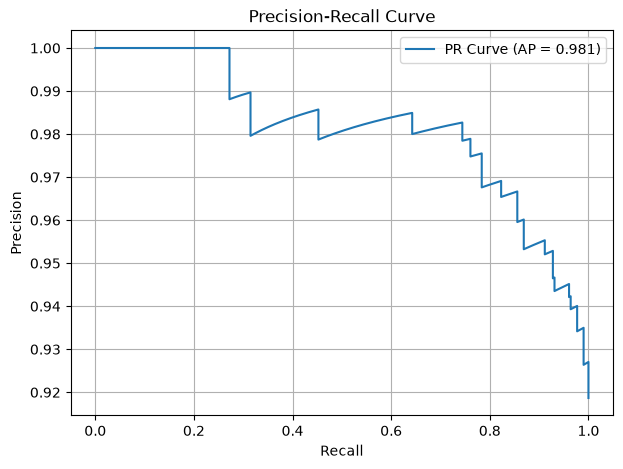

Average Precision Score: 0.981


In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# Calculate Precision and Recall values
precision_values, recall_values, thresholds = precision_recall_curve(
    y_test, y_prob
)

# Calculate Average Precision Score
avg_precision = average_precision_score(y_test, y_prob)

# Plot Precision-Recall Curve
plt.figure(figsize=(7, 5))

plt.plot(
    recall_values,
    precision_values,
    label=f"PR Curve (AP = {avg_precision:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid()
plt.savefig("results/precision_recall_curve.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Average Precision Score:", np.round(avg_precision,3))

#### Model Evaluation: Precision-Recall (PR) Curve Analysis

To complement our ROC analysis, we evaluated the model using a **Precision-Recall (PR) Curve** and calculated the **Average Precision (AP)** score. While ROC curves can sometimes provide an overly optimistic view on imbalanced datasets, the PR curve focuses directly on the prediction quality of the positive class (patients with Chronic Kidney Disease).

##### Key Insights & Performance Interpretation:

* **Exceptional Precision Quality ($\text{AP} = 0.981$):** The model achieves an outstanding Average Precision of **0.981**. This means that across all operational thresholds, the model maintains an extremely high ratio of true positive predictions compared to total positive predictions, minimizing false alarms.
* **Zoomed-In Precision Axis:** Note that the precision axis is focused heavily on the high-end spectrum (**0.92 to 1.00**). Even as the model's capacity to find all sick patients increases (moving along the Recall axis from 0.0 to 1.0), the precision remains remarkably stable and drops no lower than roughly 0.92.
* **Data Imbalance Robustness:** In medical diagnostics, datasets are frequently imbalanced (fewer positive disease cases than healthy ones). An AP score of nearly 0.98 confirms that our model's high performance is robust and highly dependable, avoiding the pitfalls of false positives that could lead to clinical over-diagnosis.

##### Clinical Implementation & Threshold Tuning:
The PR curve explicitly shows how aggressively we can catch disease cases without overwhelming doctors with false alarms:
* **High Recall (Comprehensive Screening):** We can push the model to a Recall of 1.0 (catching 100% of the CKD patients in the dataset) while still maintaining a Precision of approximately 0.92. This ensures maximum patient coverage with minimal false positives.
* **High Precision (Definitive Diagnosis):** By selecting thresholds at the top of the curve, we achieve a Precision of 1.00. Any patient flagged at this setting is guaranteed to have CKD, making it ideal for automating high-confidence clinical alerts.

## Final evaluation summary

In [ ]:
# Display all evaluation metrics together

print("FINAL MODEL EVALUATION")
print("----------------------")
print("Accuracy:", np.round(accuracy,3))
print("Precision:", np.round(precision,3))
print("Recall:", np.round(recall,3))
print("F1 Score:", np.round(f1,3))
print("ROC-AUC Score:", np.round(roc_auc,3))
print("Average Precision Score:", np.round(avg_precision,3))

FINAL MODEL EVALUATION
----------------------
Accuracy: 0.919
Precision: 0.937
Recall: 0.977
F1 Score: 0.957
ROC-AUC Score: 0.836
Average Precision Score: 0.981
